## Plot the Data

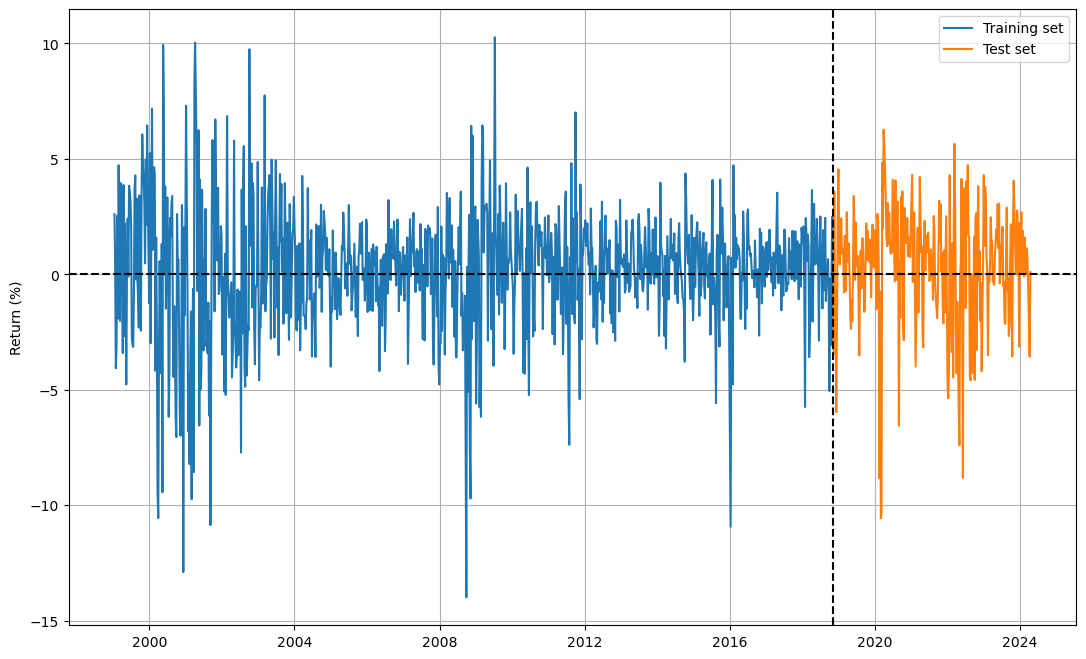

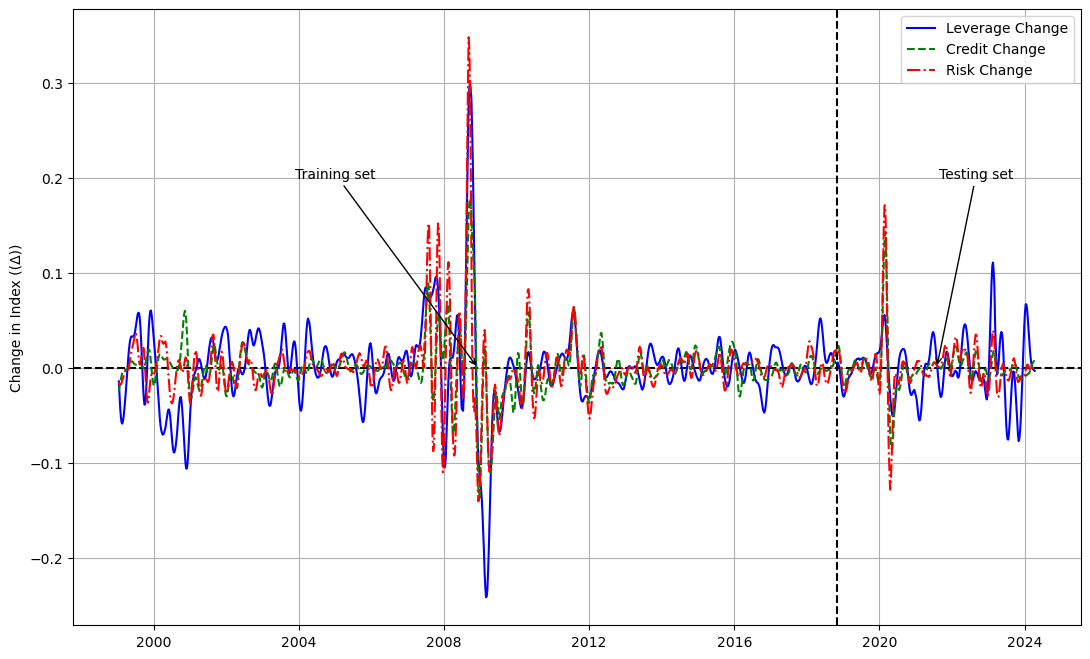

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data
data = pd.read_csv("weekly-nasdaq-return-project.csv")
data['date'] = pd.to_datetime(data['date'])

# Training and testing splits
TT = 1000
train_data = data.iloc[:TT]
test_data = data.iloc[TT:]

# Create the plot for NASDAQ returns
plt.figure(figsize=(13, 8))  # Customized figure size
plt.plot(train_data['date'], train_data['nasdaq_prch'], label='Training set')
plt.plot(test_data['date'], test_data['nasdaq_prch'], label='Test set')
plt.axhline(y=0, color='k', linestyle='--')
plt.axvline(x=train_data['date'].iloc[-1], color='k', linestyle='--')

plt.ylabel('Return (%)')
plt.legend()
plt.grid(True)

plt.savefig('NASDAQ_Returns.png', dpi=300)  
plt.show()

plt.figure(figsize=(13, 8)) 

# Plots for NFCI subindices
plt.axhline(y=0, color='k', linestyle='--')
plt.plot(train_data['date'], train_data['nfci_lev_ch'], label='Leverage Change', linestyle='-', color='blue')
plt.plot(test_data['date'], test_data['nfci_lev_ch'], linestyle='-', color='blue')
plt.plot(train_data['date'], train_data['nfci_cred_ch'], label='Credit Change', linestyle='--', color='green')
plt.plot(test_data['date'], test_data['nfci_cred_ch'], linestyle='--', color='green')
plt.plot(train_data['date'], train_data['nfci_risk_ch'], label='Risk Change', linestyle='-.', color='red')
plt.plot(test_data['date'], test_data['nfci_risk_ch'], linestyle='-.', color='red')


transition_date = train_data['date'].iloc[-1]
plt.axvline(x=transition_date, color='k', linestyle='--')

plt.annotate('Training set', xy=(train_data['date'].iloc[int(0.5*TT)], 0), 
             xytext=(train_data['date'].iloc[int(0.3*TT)], 0.2),
             arrowprops=dict(facecolor='black', arrowstyle='->'), ha='center')
plt.annotate('Testing set', xy=(test_data['date'].iloc[int(0.5*(len(data) - TT))], 0), 
             xytext=(test_data['date'].iloc[int(0.7*(len(data) - TT))], 0.2),
             arrowprops=dict(facecolor='black', arrowstyle='->'), ha='center')
plt.ylabel('Change in Index ((Δ))')
plt.legend()
plt.grid(True)

plt.savefig('NCFI_Subindexes.png', dpi=300) 
plt.show()

## Binary Classfication Problem

In [2]:
# Read the data
raw_data = pd.read_csv("weekly-nasdaq-return-project.csv")

raw_data['date'] = pd.to_datetime(raw_data['date'])

# Summary
print(raw_data['nasdaq_prch'].describe())

# Categorizing the returns into binary classes
raw_data['nasdaq_cat'] = (raw_data['nasdaq_prch'] > 0).astype(int)

# Creating lagged data
lag_data = raw_data.copy()
for col in lag_data.columns.difference(['date', 'nasdaq_cat']):
    lag_data[col] = lag_data[col].shift(1)

lag_data = lag_data.dropna().reset_index(drop=True)

print(lag_data['nasdaq_cat'].value_counts())

# Prepare the data
data = lag_data.drop(['date', 'nasdaq_prch'], axis=1).dropna()

TT = 1000
train_data = data.iloc[:TT]
test_data = data.iloc[TT:]


# Define the sigmoid function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Loss function: Log likelihood function
def log_likelihood(pred, y):
    return -np.sum(y * np.log(pred) + (1 - y) * np.log(1 - pred)) / len(pred)


count    1275.000000
mean        0.184009
std         2.665257
min       -13.984395
25%        -1.124202
50%         0.493489
75%         1.710979
max        10.263706
Name: nasdaq_prch, dtype: float64
1    745
0    529
Name: nasdaq_cat, dtype: int64


In [3]:
# Lipschitz Constant

X = train_data.drop('nasdaq_cat', axis=1).values

XTX = np.dot(X.T, X)

eigen_values = np.linalg.eigvals(XTX)
lambda_max = max(eigen_values)

num_classes = len(np.unique(train_data['nasdaq_cat']))
L = (1 / 4) * lambda_max

print(1 / L)

1.269266780277429


## GD with Fixed Learning Rate

In [17]:
import time

# Gradient descent with a fixed learning rate
def gd_fixed_eta(X, y, eta, max_iter, tol=1e-10):
    n_samples, n_features = X.shape
    
    # Initialize weights
    w = np.zeros((n_features, 1))
    loss_hist = np.zeros(max_iter)
    error = np.zeros(max_iter)
    
    # Store weight updates
    w_updates = np.zeros((max_iter, n_features))
    
    # Start the timer
    timer_start = time.time()
    
    for iter in range(max_iter):
        logits = np.dot(X, w)
        prob = sigmoid(logits)
        
        # Log likelihood loss
        loss_hist[iter] = log_likelihood(prob, y)
        pred = (prob > 0.5).astype(int)
        error[iter] = np.mean(pred.flatten() != y)
        
        # Convergence check
        if iter > 0 and abs(loss_hist[iter - 1] - loss_hist[iter]) < tol:
            time_elapsed = time.time() - timer_start 
            print(f"Algorithm converged after {iter} iterations. Time elapsed: {time_elapsed:.2f} seconds. Loss: {loss_hist[iter]:.5f}, Training Error: {error[iter]:.5f}")
            break
        
        # Gradient
        grad = np.dot(X.T, (prob - y)) / n_samples
        w -= eta * grad
        
        # Store the weight updates
        w_updates[iter] = w.T
        
        # If maximum iteration reached without convergence
        if iter == max_iter - 1:
            time_elapsed = time.time() - timer_start 
            print(f"Maximum iterations ({max_iter}) reached without convergence. Time elapsed: {time_elapsed:.2f} seconds. Last Loss: {loss_hist[iter]:.5f}, Last Training Error: {error[iter]:.5f}")
    
    return {
        'w': w, 
        'loss_hist': loss_hist[:iter+1], 
        'error': error[:iter+1], 
        'convg_iter': iter,
        'w_updates': w_updates[:iter+1]
    }

y = train_data['nasdaq_cat'].values.reshape(-1, 1)
X = train_data.drop('nasdaq_cat', axis=1).values

# Estimate learning rate from Lipschitz Constant
XTX = np.dot(X.T, X)
lambda_max = np.max(np.linalg.eigvals(XTX))
L = (1 / 4) * lambda_max
eta = 1 / L

# Run gradient descent
results_gd_fix = gd_fixed_eta(X, y, eta, max_iter=int(1e5), tol=1e-8)

Algorithm converged after 19729 iterations. Time elapsed: 17.65 seconds. Loss: 0.67374, Training Error: 0.48992


## AGD with Fixed Learning Rates

In [5]:
# Accelerated Gradient Descent
def accelerated_gd(X, y, L_f, max_iter, tol=1e-8):
    n_samples, n_features = X.shape
    
    # Initialize weights
    w = np.zeros((n_features, 1))
    y_t = np.copy(w)
    tau_t = 1
    
    loss_hist = np.zeros(max_iter)
    error = np.zeros(max_iter)
    
    # Store weight updates
    w_updates = np.zeros((max_iter, n_features))
    
    # Start the timer
    timer_start = time.time()
    
    for iter in range(max_iter):
        logits = np.dot(X, y_t)
        prob = sigmoid(logits)
        
        # Log likelihood loss
        loss_hist[iter] = log_likelihood(prob, y)
        pred = (prob > 0.5).astype(int)
        error[iter] = np.mean(pred.flatten() != y)
        
        # Gradient
        grad = np.dot(X.T, (prob - y)) / n_samples
        x_next = y_t - (1 / L_f) * grad
        
        if iter > 0 and abs(loss_hist[iter - 1] - loss_hist[iter]) < tol:
            time_elapsed = time.time() - timer_start  
            print(f"Algorithm converged after {iter} iterations. Time elapsed: {time_elapsed:.2f} seconds. Loss: {loss_hist[iter]:.5f}, Training Error: {error[iter]:.5f}")
            break
        
        tau_next = (1 + np.sqrt(4 * tau_t**2 + 1)) / 2
        y_t = x_next + ((tau_t - 1) / tau_next) * (x_next - w)
        
        w = x_next
        tau_t = tau_next
        
        # Store the weight updates
        w_updates[iter] = w.T
        
        if iter == max_iter - 1:
            time_elapsed = time.time() - timer_start  
            print(f"Maximum iterations ({max_iter}) reached without convergence. Time elapsed: {time_elapsed:.2f} seconds. Last Loss: {loss_hist[iter]:.5f}, Last Training Error: {error[iter]:.5f}")
    
    return {
        'w': w, 
        'loss_hist': loss_hist[:iter+1], 
        'error': error[:iter+1], 
        'convg_iter': iter,
        'w_updates': w_updates[:iter+1]
    }


y = train_data['nasdaq_cat'].values.reshape(-1, 1)
X = train_data.drop('nasdaq_cat', axis=1).values


XTX = np.dot(X.T, X)
lambda_max = np.max(np.linalg.eigvals(XTX))
L = (1 / 4) * lambda_max

# Run accelerated gradient descent
results_acd = accelerated_gd(X, y, L, max_iter=int(1e5), tol=1e-8)

Algorithm converged after 474 iterations. Time elapsed: 0.44 seconds. Loss: 0.67366, Training Error: 0.49104


## AGD with Backtracking Linesearch

In [6]:
# Accelerated Gradient Descent with backtracking line search
def accelerated_gd_backtracking(X, y, eta, max_iter, tol=1e-8, beta=0.95):
    n_samples, n_features = X.shape
    
    # Initialize weights and variables
    w = np.zeros((n_features, 1))
    y_t = np.copy(w)
    tau_t = 1
    loss_hist = np.zeros(max_iter)
    error = np.zeros(max_iter)
    eta_hist = np.zeros(max_iter)
    
    # Store weight updates
    w_updates = np.zeros((max_iter, n_features))
    
    # Start the timer
    timer_start = time.time()
    
    for iter in range(max_iter):
        logits = np.dot(X, y_t)
        prob = sigmoid(logits)
        current_loss = log_likelihood(prob, y)
        
        # Store eta value
        eta_hist[iter] = eta
        
        # Backtracking line search
        if iter > 0 and current_loss >= loss_hist[iter - 1] and eta > 1e-10:
            eta *= beta
        
        loss_hist[iter] = current_loss
        pred = (prob > 0.5).astype(int)
        error[iter] = np.mean(pred.flatten() != y)
        
        # Gradient
        grad = np.dot(X.T, (prob - y)) / n_samples
        x_next = y_t - eta * grad
        
        if iter > 0 and abs(loss_hist[iter - 1] - loss_hist[iter]) < tol:
            time_elapsed = time.time() - timer_start  
            print(f"Algorithm converged after {iter} iterations. Time elapsed: {time_elapsed:.2f} seconds. Loss: {loss_hist[iter]:.5f}, Training Error: {error[iter]:.5f}, Final Eta: {eta_hist[iter]:.5f}")
            break
        
        tau_next = (1 + np.sqrt(1 + 4 * tau_t**2)) / 2
        y_t = x_next + ((tau_t - 1) / tau_next) * (x_next - w)
        
        w = x_next
        tau_t = tau_next
        
        # Store the weight updates
        w_updates[iter] = w.T
        
        # If maximum iteration reached 
        if iter == max_iter - 1:
            time_elapsed = time.time() - timer_start  
            print(f"Maximum iterations ({max_iter}) reached without convergence. Time elapsed: {time_elapsed:.2f} seconds. Last Loss: {loss_hist[iter]:.5f}, Last Training Error: {error[iter]:.5f}, Final Eta: {eta_hist[iter]:.5f}")
    
    return {
        'w': w, 
        'loss_hist': loss_hist[:iter+1], 
        'error': error[:iter+1], 
        'eta_hist': eta_hist[:iter+1], 
        'convg_iter': iter,
        'w_updates': w_updates[:iter+1]
    }

# Run agd with backtracking line search
results_acd_back = accelerated_gd_backtracking(X, y, eta=1/L, max_iter=int(1e5), tol=1e-8, beta=0.9)

Algorithm converged after 3075 iterations. Time elapsed: 2.94 seconds. Loss: 0.67493, Training Error: 0.49202, Final Eta: 0.00000


## SGD with Mini-Batch + Backtracking Linesearch

In [7]:
# Mini-Batch Stochastic Gradient Descent with Backtracking Line Search
def mini_batch_sgd_backtrack(X, y, batch_size, eta, beta, max_iter, tol=1e-8):
    n_samples, n_features = X.shape
    
    # Initialize weights
    w = np.zeros((n_features, 1))
    loss_hist = np.zeros(max_iter)
    error = np.zeros(max_iter)
    eta_hist = np.zeros(max_iter) 
    
    # Store weight updates
    w_updates = np.zeros((max_iter, n_features))
    
    timer_start = time.time()
    
    for iter in range(max_iter):
        # Sample a mini-batch
        np.random.seed(66666)
        idx = np.random.choice(n_samples, batch_size, replace=True)
        X_batch = X[idx]
        y_batch = y[idx].reshape(-1, 1)
        
        logits = np.dot(X_batch, w)
        prob = sigmoid(logits)
        current_loss = log_likelihood(prob, y_batch)
        
        # Store eta value
        eta_hist[iter] = eta
        
        if iter > 0 and current_loss >= loss_hist[iter - 1] and eta > 1e-9:
            eta *= beta  # Reduce eta
        
        loss_hist[iter] = current_loss
        pred = (prob > 0.5).astype(int)
        error[iter] = np.mean(pred.flatten() != y_batch.flatten())
        
        # Gradient
        grad = np.dot(X_batch.T, (prob - y_batch)) / batch_size
        w -= eta * grad
        
        # Store the weight updates
        w_updates[iter] = w.T
        
        if iter > 0 and abs(loss_hist[iter - 1] - loss_hist[iter]) < tol:
            time_elapsed = time.time() - timer_start  
            print(f"Algorithm converged after {iter} iterations. Time elapsed: {time_elapsed:.2f} seconds. Loss: {loss_hist[iter]:.5f}, Training Error: {error[iter]:.5f}, Final Eta: {eta_hist[iter]:.5f}")
            break
        
        # If maximum iteration
        if iter == max_iter - 1:
            time_elapsed = time.time() - timer_start 
            print(f"Maximum iterations ({max_iter}) reached without convergence. Time elapsed: {time_elapsed:.2f} seconds. Last Loss: {loss_hist[iter]:.5f}, Last Training Error: {error[iter]:.5f}, Final Eta: {eta_hist[iter]:.5f}")
    
    return {
        'w': w, 
        'loss_hist': loss_hist[:iter+1], 
        'error': error[:iter+1], 
        'eta_hist': eta_hist[:iter+1], 
        'convg_iter': iter,
        'w_updates': w_updates[:iter+1]
    }


eta_start = 1 / L
max_iter = int(1e5)
beta = 0.95

# Different batch sizes
batch_sizes = np.round(TT * np.array([0.3, 0.4, 0.5])).astype(int)

results_sgd_back = {}

# Run model for each batch size
for batch_size in batch_sizes:
    results_sgd_back[str(batch_size)] = mini_batch_sgd_backtrack(X, y, batch_size, eta_start, beta, max_iter, tol=1e-8)

Algorithm converged after 8458 iterations. Time elapsed: 0.30 seconds. Loss: 0.67869, Training Error: 0.44333, Final Eta: 1.26927
Algorithm converged after 8854 iterations. Time elapsed: 0.33 seconds. Loss: 0.68034, Training Error: 0.42750, Final Eta: 1.26927
Algorithm converged after 15143 iterations. Time elapsed: 0.63 seconds. Loss: 0.68315, Training Error: 0.40600, Final Eta: 1.26927


## AdapGrad + Mini-batch + Backline Search

In [8]:
# Mini-batch SGD with AdaGrad and backtracking line search
def mini_batch_sgd_adagrad_backtrack(X, y, batch_size, eta, beta, max_iter, epsilon=1e-8, tol=1e-8):
    n_samples, n_features = X.shape
    
    # Initialize weights
    w = np.zeros((n_features, 1))
    v = np.zeros((n_features, 1)) 
    
    loss_hist = np.zeros(max_iter)
    error = np.zeros(max_iter)
    eta_hist = np.zeros(max_iter)
    
    # Store weight updates
    w_updates = np.zeros((max_iter, n_features))
    
    timer_start = time.time()
    
    for iter in range(max_iter):
        # Sample a mini-batch
        np.random.seed(66666)
        idx = np.random.choice(n_samples, batch_size, replace=True)
        X_batch = X[idx]
        y_batch = y[idx]
        
        logits = np.dot(X_batch, w)
        prob = sigmoid(logits)
        current_loss = log_likelihood(prob, y_batch)
        
        loss_hist[iter] = current_loss
        pred = (prob > 0.5).astype(int)
        error[iter] = np.mean(pred.flatten() != y_batch)
        
        # Store eta value
        eta_hist[iter] = eta
        
        if iter > 0 and current_loss >= loss_hist[iter - 1] and eta > 1e-9:
            eta *= beta  # Reduce eta 
        
        # Grad
        grad = np.dot(X_batch.T, (prob - y_batch)) / batch_size
        
        # Update gradient history
        v += grad**2
        
        # Update weights
        w_adjustment = (eta / np.sqrt(v + epsilon)) * grad
        w -= w_adjustment
        
        # Store the weight updates
        w_updates[iter] = w.T
        
        if iter > 0 and abs(loss_hist[iter - 1] - loss_hist[iter]) < tol:
            time_elapsed = time.time() - timer_start 
            print(f"Algorithm converged after {iter} iterations. Time elapsed: {time_elapsed:.2f} seconds. Loss: {loss_hist[iter]:.5f}, Training Error: {error[iter]:.5f}, Final Eta: {eta_hist[iter]:.5f}")
            break
        
        if iter == max_iter - 1:
            time_elapsed = time.time() - timer_start 
            print(f"Maximum iterations ({max_iter}) reached without convergence. Time elapsed: {time_elapsed:.2f} seconds. Last Loss: {loss_hist[iter]:.5f}, Last Training Error: {error[iter]:.5f}, Final Eta: {eta_hist[iter]:.5f}")
    
    return {
        'w': w, 
        'loss_hist': loss_hist[:iter+1], 
        'error': error[:iter+1], 
        'eta_hist': eta_hist[:iter+1], 
        'convg_iter': iter,
        'w_updates': w_updates[:iter+1]
    }

TT = train_data.shape[0]
batch_sizes = np.round(TT * np.array([0.3, 0.4, 0.5])).astype(int)
eta_initial = 1/L
beta = 0.95
max_iter = int(1e6)
epsilon = 1e-10

# Run model for each batch size and store results
results_adagrad_backtrack = {}
for batch_size in batch_sizes:
    print(f"Running mini-batch SGD with AdaGrad and backtracking for batch size: {batch_size}")
    results_adagrad_backtrack[str(batch_size)] = mini_batch_sgd_adagrad_backtrack(
        X, y, batch_size, eta_initial, beta, max_iter, epsilon, tol=1e-8
    )

Running mini-batch SGD with AdaGrad and backtracking for batch size: 300
Algorithm converged after 225 iterations. Time elapsed: 0.03 seconds. Loss: 0.67866, Training Error: 0.49893, Final Eta: 1.26927
Running mini-batch SGD with AdaGrad and backtracking for batch size: 400
Algorithm converged after 175 iterations. Time elapsed: 0.03 seconds. Loss: 0.68033, Training Error: 0.49719, Final Eta: 1.26927
Running mini-batch SGD with AdaGrad and backtracking for batch size: 500
Algorithm converged after 172 iterations. Time elapsed: 0.05 seconds. Loss: 0.68307, Training Error: 0.49755, Final Eta: 1.26927


## Testing Predictions

In [9]:
def predict(X, w):
    """Compute predictions using the logistic sigmoid function."""
    logits = np.dot(X, w)
    probs = sigmoid(logits)
    return (probs >= 0.5).astype(int)

# Test data preparation
X_test = test_data.drop('nasdaq_cat', axis=1).values
y_test = test_data['nasdaq_cat'].values.reshape(-1, 1)

pred_gd = predict(X_test, results_gd_fix['w'])
pred_acd = predict(X_test, results_acd['w'])
pred_acd_back = predict(X_test, results_acd_back['w'])
pred_sgd_back = predict(X_test, results_sgd_back[str(300)]['w'])
pred_adagrad_back = predict(X_test, results_adagrad_backtrack[str(300)]['w'])

# Compute the testing error rate
error_gd = np.mean(pred_gd != y_test)
error_acd = np.mean(pred_acd != y_test)
error_acd_back = np.mean(pred_acd_back != y_test)
error_sgd_back = np.mean(pred_sgd_back != y_test)
error_adagrad_back = np.mean(pred_adagrad_back != y_test)

print(f"Testing Error Rate for Gradient Descent (GD): {error_gd:.3f}")
print(f"Testing Error Rate for Accelerated Gradient Descent (AGD): {error_acd:.3f}")
print(f"Testing Error Rate for AGD with Backtracking Line Search: {error_acd_back:.3f}")
print(f"Testing Error Rate for SGD with 30% batch size: {error_sgd_back:.3f}")
print(f"Testing Error Rate for AdaGrad with 30% batch size: {error_adagrad_back:.3f}")

Testing Error Rate for Gradient Descent (GD): 0.296
Testing Error Rate for Accelerated Gradient Descent (AGD): 0.303
Testing Error Rate for AGD with Backtracking Line Search: 0.318
Testing Error Rate for SGD with 30% batch size: 0.383
Testing Error Rate for AdaGrad with 30% batch size: 0.380


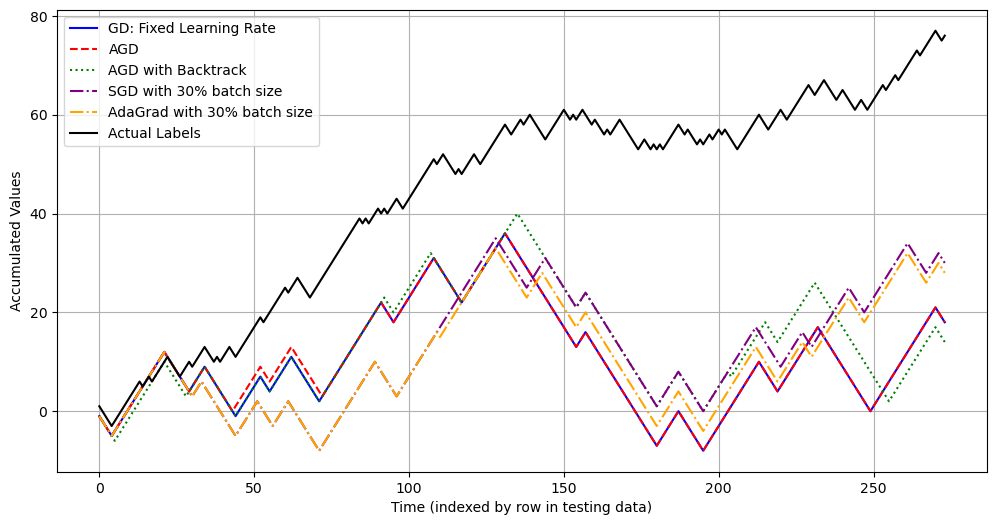

[1 0 0 0 0 1 1 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 1 0 0 0 0 1 1 1 0 1 1 1 1 0 0
 0 1 0 1 1 1 0 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 0 0 0 0 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 0 1 0 1 1 1 0 1 0 1 1 1 0 0 1 1 1 1 1 1 1 1 1 1 0 1
 1 0 0 0 0 1 0 1 1 1 1 0 0 1 1 1 1 1 1 1 1 0 0 1 1 1 0 1 1 0 0 0 0 0 1 1 1
 1 1 1 0 0 1 0 1 1 0 0 0 1 0 0 0 1 0 1 1 1 0 0 0 0 0 0 1 1 0 0 1 0 1 0 1 1
 1 1 1 0 0 1 0 0 0 1 0 1 1 0 1 1 0 1 0 0 0 0 1 1 1 1 1 1 1 0 0 0 1 1 1 1 0
 0 1 1 1 1 1 1 1 0 0 1 1 1 0 0 0 0 1 1 0 0 0 0 1 1 0 0 1 1 1 1 1 0 1 1 1 0
 1 1 1 1 1 1 0 1 1 1 1 1 0 0 1]


In [18]:
# Function to convert labels to +1 or -1 and accumulate over time
def accumulate_predictions(predictions):
    return np.cumsum(np.where(predictions == 1, 1, -1))

accum_gd = accumulate_predictions(pred_gd)
accum_acd = accumulate_predictions(pred_acd)
accum_acd_back = accumulate_predictions(pred_acd_back)
accum_sgd_back = accumulate_predictions(pred_sgd_back)
accum_adagrad_back = accumulate_predictions(pred_adagrad_back)

# Convert actual labels and accumulate
actual_labels = test_data['nasdaq_cat'].values
accum_actual = np.cumsum(np.where(actual_labels == 1, 1, -1))

# Plotting
plt.figure(figsize=(12, 6))

plt.plot(accum_gd, label='GD: Fixed Learning Rate', color='blue', linestyle='-')
plt.plot(accum_acd, label='AGD', color='red', linestyle='--')
plt.plot(accum_acd_back, label='AGD with Backtrack', color='green', linestyle=':')
plt.plot(accum_sgd_back, label='SGD with 30% batch size', color='purple', linestyle='-.')
plt.plot(accum_adagrad_back, label='AdaGrad with 30% batch size', color='orange', linestyle='-.')

plt.plot(accum_actual, label='Actual Labels', color='black', linestyle='-')

plt.xlabel('Time (indexed by row in testing data)')
plt.ylabel('Accumulated Values')
plt.legend()
plt.grid(True)
plt.show()

## Plot GD

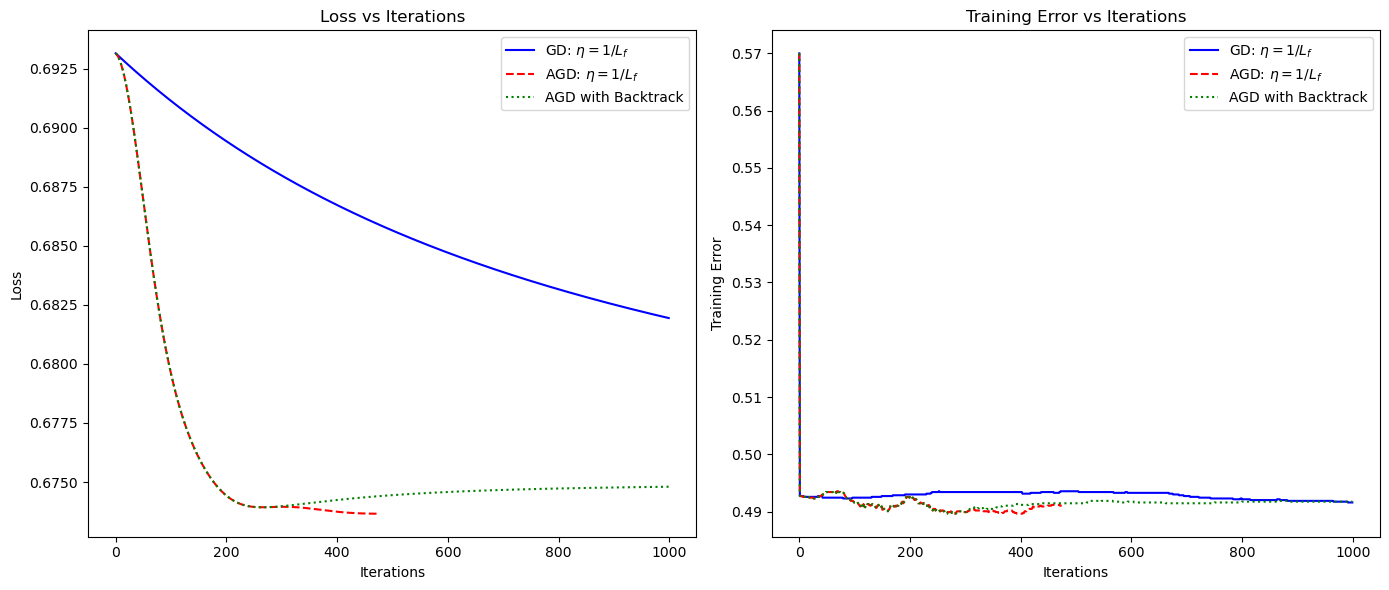

In [11]:
iterations_gd = len(results_gd_fix['loss_hist'])
iterations_acd = len(results_acd['loss_hist'])
iterations_acd_back = len(results_acd_back['loss_hist'])

# The maximum x-axis value for plotting
max_iter_plot = 1000

# Loss vs Iterations
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)

plt.plot(range(iterations_gd)[:max_iter_plot], results_gd_fix['loss_hist'][:max_iter_plot], 
         label='GD: $\eta = 1 / L_f$', color='blue', linestyle='-')

plt.plot(range(iterations_acd)[:max_iter_plot], results_acd['loss_hist'][:max_iter_plot], 
         label='AGD: $\eta = 1 / L_f$', color='red', linestyle='--')

plt.plot(range(iterations_acd_back)[:max_iter_plot], results_acd_back['loss_hist'][:max_iter_plot], 
         label='AGD with Backtrack', color='green', linestyle=':')

plt.title('Loss vs Iterations')
plt.xlabel('Iterations')
plt.ylabel('Loss')
plt.legend()

# Training Error vs Iterations
plt.subplot(1, 2, 2)

plt.plot(range(iterations_gd)[:max_iter_plot], results_gd_fix['error'][:max_iter_plot], 
         label='GD: $\eta = 1 / L_f$', color='blue', linestyle='-')

plt.plot(range(iterations_acd)[:max_iter_plot], results_acd['error'][:max_iter_plot], 
         label='AGD: $\eta = 1 / L_f$', color='red', linestyle='--')

plt.plot(range(iterations_acd_back)[:max_iter_plot], results_acd_back['error'][:max_iter_plot], 
         label='AGD with Backtrack', color='green', linestyle=':')

plt.title('Training Error vs Iterations')
plt.xlabel('Iterations')
plt.ylabel('Training Error')
plt.legend()

plt.tight_layout()
plt.show()

## Plot for SGC

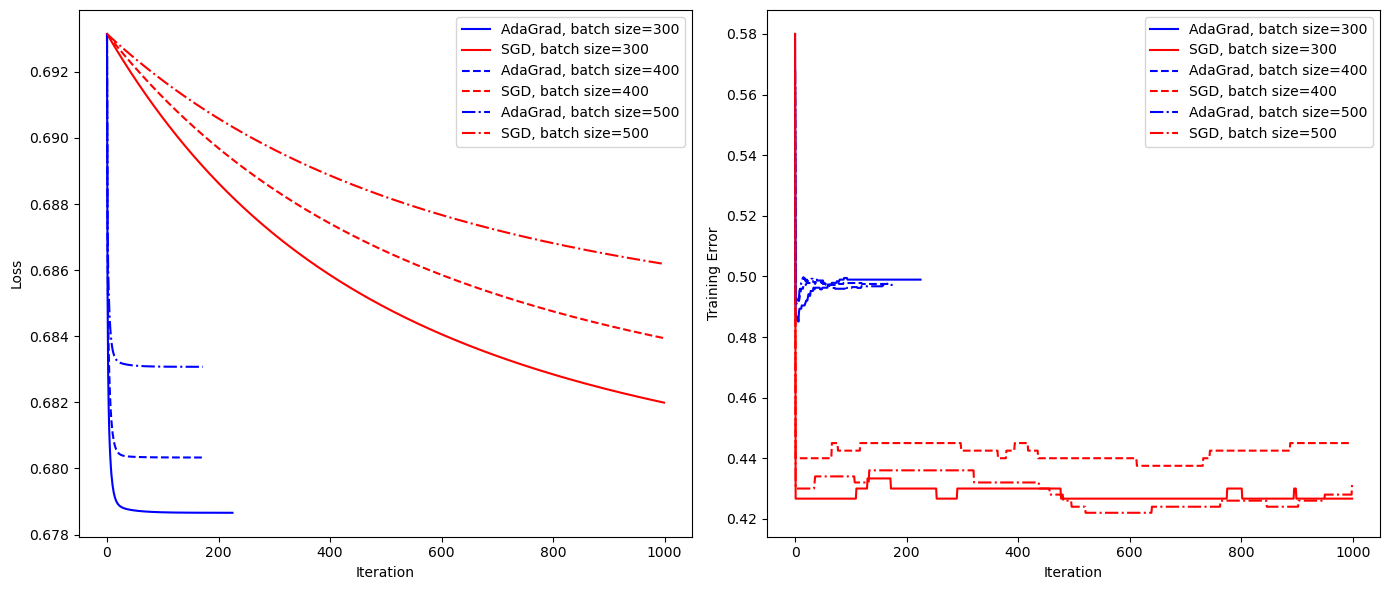

In [12]:
import matplotlib.pyplot as plt

batch_sizes = np.round(TT * np.array([0.3, 0.4, 0.5])).astype(int)
max_iter = int(1e6)
max_plot_iter = 1000

plt.figure(figsize=(14, 6))

# Loss vs Iteration
plt.subplot(1, 2, 1)
for i, batch_size in enumerate(batch_sizes):
    
    line_style = ['-', '--', '-.'][i]

    adagrad_loss = results_adagrad_backtrack[str(batch_size)]['loss_hist']
    plt.plot(adagrad_loss[:max_plot_iter], line_style, label=f'AdaGrad, batch size={batch_size}', color='blue')

    sgd_loss = results_sgd_back[str(batch_size)]['loss_hist']
    plt.plot(sgd_loss[:max_plot_iter], line_style, label=f'SGD, batch size={batch_size}', color='red')

plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.legend()

# Training Error vs Iteration
plt.subplot(1, 2, 2)
for i, batch_size in enumerate(batch_sizes):
   
    line_style = ['-', '--', '-.'][i]

    adagrad_error = results_adagrad_backtrack[str(batch_size)]['error']
    plt.plot(adagrad_error[:max_plot_iter], line_style, label=f'AdaGrad, batch size={batch_size}', color='blue')

    sgd_error = results_sgd_back[str(batch_size)]['error']
    plt.plot(sgd_error[:max_plot_iter], line_style, label=f'SGD, batch size={batch_size}', color='red')

plt.xlabel('Iteration')
plt.ylabel('Training Error')
plt.legend()

plt.tight_layout()
plt.show()